# Lab03 — Phân khúc khách hàng và diễn giải

Notebook thực hiện từng bước bằng các module nhỏ, có phân tích riêng K=5/6/9, nhiều seed, Gender và marketing. Chạy từ trên xuống. Các đề xuất marketing là giả thuyết.

Mỗi lần Run All tạo một thư mục mới có ngày giờ và mã riêng trong results/runs. Thư mục tham chiếu của báo cáo được giữ để đọc, các ô notebook ghi vào output mới.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from uuid import uuid4
from datetime import datetime, timedelta, timezone
from hashlib import sha256
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Lab03/src/config.yaml").is_file())
if str(repo) not in sys.path: sys.path.insert(0,str(repo))
from Lab03.src.preprocessing import LAB_DIR, prepare_data
from Lab03.src.eda import analyze
from Lab03.src.train import train_model
from Lab03.src.tuning import tune
from Lab03.src.evaluate import silhouette_samples, cluster_profiles
from Lab03.src.analysis import describe_segments, gender_distribution, stability_analysis, compare_hierarchical
from Lab03.src.visualization import plot_comparison, plot_clusters, plot_income_spending, plot_silhouette, plot_dendrogram
config = yaml.safe_load((LAB_DIR / "src/config.yaml").read_text(encoding="utf-8"))
started = datetime.now(timezone(timedelta(hours=7)))
run_id = started.strftime("%Y-%m-%d_%H-%M-%S") + "_notebook_" + uuid4().hex[:8]
output = LAB_DIR / "results/runs" / run_id
output.mkdir(parents=True,exist_ok=False)
(output / "config.yaml").write_text(yaml.safe_dump(config),encoding="utf-8")
manifest = {
    "run_id": run_id, "status": "running", "started_at": started.isoformat(),
    "dataset_sha256": sha256((LAB_DIR / config["data"]["path"]).read_bytes()).hexdigest(),
}
(output / "run.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
print("Notebook output:",output)
figures = output / "figures"
figures.mkdir(parents=True,exist_ok=True)
for folder in ["model", "clusters", "k_selection", "validation"]:
    (output / folder).mkdir(exist_ok=True)
features = config["data"]["features"]
raw = pd.read_csv(LAB_DIR / config["data"]["path"])
print(raw.head().to_string(index=False))
print(raw.isna().sum().to_string())


Notebook output: E:\ML_Nhóm6\Lab03\results\runs\2026-11-18_20-31-41_notebook_273e6c72
 CustomerID Gender  Age  Annual Income (k$)  Spending Score (1-100)
          1   Male   19                  15                      39
          2   Male   21                  15                      81
          3 Female   20                  16                       6
          4 Female   23                  16                      77
          5 Female   31                  17                      40
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0


## 1. EDA và chuẩn hóa

Giữ ngoại lệ IQR hợp lệ. Gender chưa tham gia khoảng cách, chỉ mô tả sau phân cụm. Chuẩn hóa toàn bộ mẫu vì đây là phân cụm mô tả.

               feature  iqr_outlier_count
                   Age                  0
    Annual Income (k$)                  2
Spending Score (1-100)                  0
               feature  mean     scale
                   Age 38.85 13.934041
    Annual Income (k$) 60.56 26.198977
Spending Score (1-100) 50.20 25.758882
Standardized means: [-1.02140518e-16 -2.13162821e-16 -1.46549439e-16] standard deviations: [1. 1. 1.]


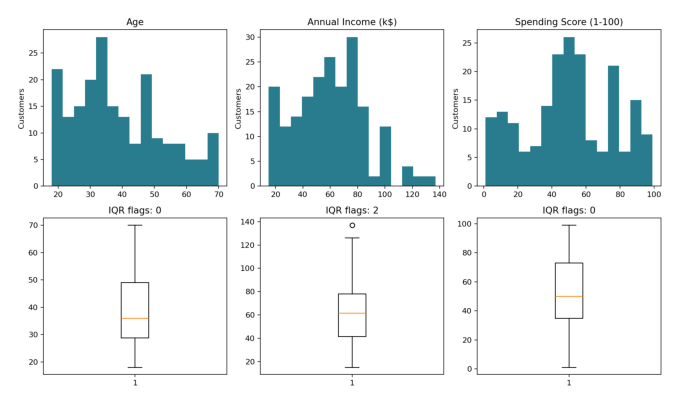

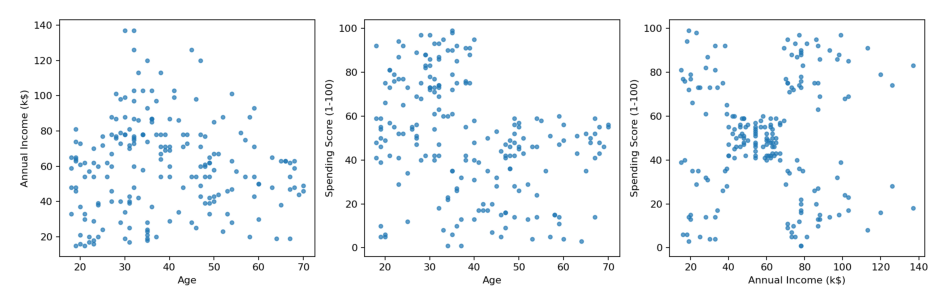

In [2]:
flags = analyze(raw,features,figures)
frame,X,scaling = prepare_data(config,output / "preprocessing")
print(flags.to_string(index=False))
print(scaling.to_string(index=False))
print("Standardized means:",X.mean(axis=0),"standard deviations:",X.std(axis=0))
for name in ["eda_overview.png","eda_feature_pairs.png"]:
    plt.figure(figsize=(12,5))
    plt.imshow(plt.imread(figures / name))
    plt.axis("off")
    plt.show()


## 2. Thử K và đối chiếu Elbow

Chọn theo Silhouette, rồi xem inertia và khả năng diễn giải. Các giá trị K được thử trên200 khách của Mall_Customers.csv.

 k  silhouette    inertia  n_iter  converged  inertia_drop_percent
 2    0.335472 389.386189       7       True                   NaN
 3    0.357793 295.212246       4       True             24.185229
 4    0.403958 205.225147       7       True             30.482170
 5    0.416643 168.247580       8       True             18.018049
 6    0.427428 133.868334      14       True             20.433724
 7    0.417232 117.011555      13       True             12.592059
 8    0.408525 104.127611       7       True             11.010830
 9    0.420786  92.293165       7       True             11.365329
10    0.399550  81.963483       6       True             11.192250
K=5: Silhouette=0.4166, inertia=168.248
K=6: Silhouette=0.4274, inertia=133.868
K=9: Silhouette=0.4208, inertia=92.293
Selected   0   1   2   3   4   5
K5                              
0          0   0  29   0   1  24
1          0  45   2   0   0   0
2          0   0   1  39   0   0
3         33   0   6   0   0   0
4          0 

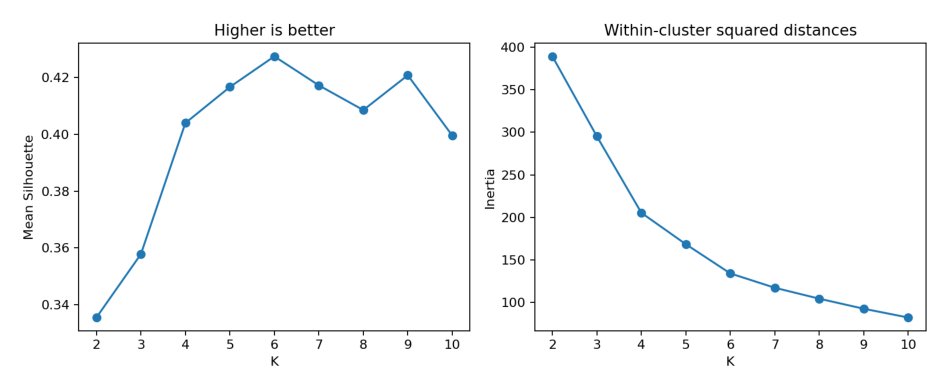

In [3]:
model,comparison = tune(X,config["kmeans"])
comparison["inertia_drop_percent"] = -comparison.inertia.pct_change()*100
print(comparison.to_string(index=False))
plot_comparison(comparison,figures / "silhouette_by_k.png")
plt.figure(figsize=(12,5))
plt.imshow(plt.imread(figures / "silhouette_by_k.png"))
plt.axis("off")
plt.show()
for k in [5,6,9]:
    row = comparison.loc[comparison.k==k].iloc[0]
    print(f"K={k}: Silhouette={row.silhouette:.4f}, inertia={row.inertia:.3f}")
alternative = train_model(X,5,config["kmeans"])
print(pd.crosstab(alternative.labels_,model.labels_,rownames=["K5"],colnames=["Selected"]).to_string())


**Nhận xét.** Đọc bảng K mới và độ giảm inertia để xem vùng Elbow. Chênh lệch Silhouette nhỏ cần được trình bày cùng độ ổn định nhiều seed. K=6 của dữ liệu cũ không được chuyển sang bộ mới.

## 3. Profile, tên nhóm và giả thuyết marketing

Quy tắc đặt tên dựa vào trung bình gốc, không dùng số nhãn cụm để gán tên. Các ngưỡng tên nhóm được ghi trong báo cáo.

In [4]:
profiles = describe_segments(cluster_profiles(frame,model.labels_,features),features)
customers = frame.assign(cluster=model.labels_,silhouette=silhouette_samples(X,model.labels_))
customers = customers.merge(profiles[["cluster","segment"]],on="cluster")
profiles.to_csv(output / "clusters/cluster_profiles.csv",index=False)
print(profiles.to_string(index=False))
overall = frame[features].mean()
for row in profiles.to_dict("records"):
    print(row["segment"],"|",row["customer_count"],"khách")
    for feature in features:
        print(" ",feature,round(row[feature+"_mean"],2),"so với toàn mẫu",round(overall[feature],2))
    print(" Giả thuyết:",row["marketing_hypothesis"])


 cluster  customer_count  Age_mean  Annual Income (k$)_mean  Spending Score (1-100)_mean                                    segment                                                   marketing_hypothesis
       0              33 41.939394                88.939394                    16.969697       Thu nhập trên TB mẫu – Chi tiêu thấp      Khảo sát nhu cầu, thử ưu đãi cá nhân hóa và đo mức tăng chi tiêu.
       1              45 56.333333                54.266667                    49.066667 Lớn tuổi – Thu nhập và chi tiêu trung bình             Thử dịch vụ thuận tiện và chương trình duy trì khách hàng.
       2              38 26.684211                57.578947                    47.789474      Trẻ – Thu nhập và chi tiêu trung bình                 Thử giới thiệu sản phẩm mới và chương trình tích điểm.
       3              39 32.692308                86.538462                    82.128205        Thu nhập trên TB mẫu – Chi tiêu cao     Ưu tiên trải nghiệm VIP, quyền lợi thành viên và bán

## 4. Trực quan 2D, 3D và Silhouette từng cụm

2D có thể chồng lấn do bỏ trục tuổi. 3D dùng đơn vị gốc và hiển thị tâm, còn mô hình học trên z-score. Silhouette âm gợi ý khách sát ranh giới cần kiểm tra.

             mean       min  count
cluster                           
0        0.328849 -0.019350     33
1        0.491287  0.148356     45
2        0.393474  0.044201     38
3        0.504887  0.282285     39
4        0.294389 -0.065183     21
5        0.487541 -0.008341     24


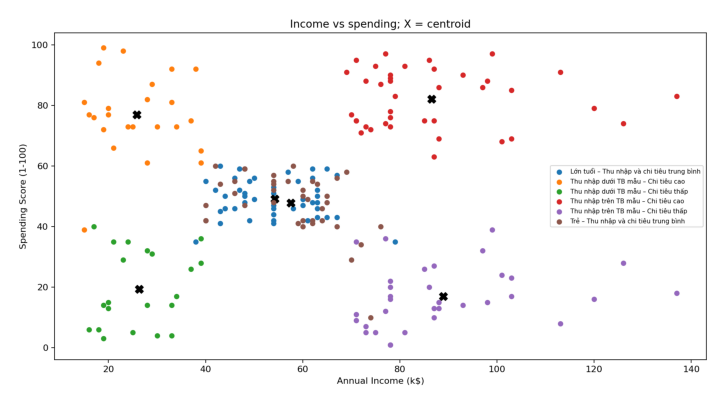

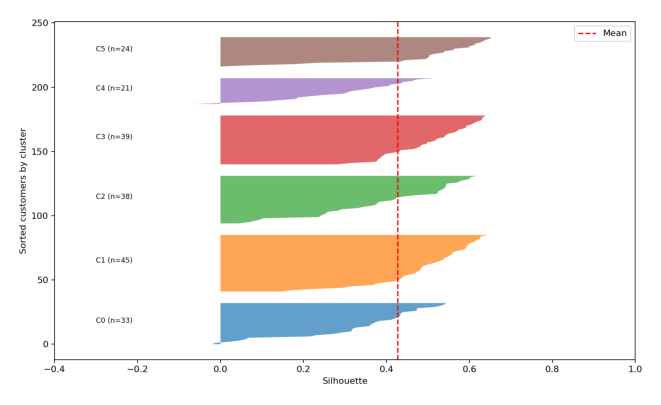

<Interactive figure>

In [5]:
plot_income_spending(customers,features,figures / "income_spending.png")
plot_silhouette(customers,figures / "silhouette_clusters.png")
for name in ["income_spending.png","silhouette_clusters.png"]:
    plt.figure(figsize=(11,5))
    plt.imshow(plt.imread(figures / name))
    plt.axis("off")
    plt.show()
figure=plot_clusters(customers,features,config["data"]["id_column"],figures / "customer_clusters_3d.html")
figure.show()
print(customers.groupby("cluster").silhouette.agg(["mean","min","count"]).to_string())


## 5. Gender theo cụm

Đọc số lượng cùng tỷ lệ, tránh suy diễn nhân quả từ khác biệt của mẫu nhỏ.

In [6]:
gender=gender_distribution(customers)
gender.to_csv(output / "clusters/gender_by_cluster.csv",index=False)
print(gender.to_string(index=False))
print("Overall Gender counts:",frame.Gender.value_counts().to_dict())


 cluster  Female  Male  Female_share  Male_share
       0      14    19      0.424242    0.575758
       1      26    19      0.577778    0.422222
       2      24    14      0.631579    0.368421
       3      21    18      0.538462    0.461538
       4      13     8      0.619048    0.380952
       5      14    10      0.583333    0.416667
Overall Gender counts: {'Female': 112, 'Male': 88}


## 6. Độ ổn định theo seed

Chạy lại toàn bộ các K với 10 seed trên dữ liệu đã lọc. Tách độ ổn định chọn K khỏi ARI khi cố định K đã chọn. ARI không phụ thuộc hoán vị số nhãn.

In [7]:
stability,pairs=stability_analysis(X,config["kmeans"],config["analysis"]["seeds"],model.labels_,model.n_clusters)
print(stability.to_string(index=False))
print("K selection frequencies:",stability.selected_k.value_counts().to_dict())
print("Pairwise fixed-K ARI:",pairs.ari.describe().to_dict())
stability.to_csv(output / "validation/seed_stability.csv",index=False)
pairs.to_csv(output / "validation/pairwise_ari.csv",index=False)


 seed  selected_k  silhouette  ari_selected_vs_reference  fixed_k  ari_fixed_vs_reference
    0           6    0.427428                   1.000000        6                1.000000
    1           6    0.427428                   1.000000        6                1.000000
    2           6    0.428417                   0.989319        6                0.989319
    3           6    0.427428                   1.000000        6                1.000000
    4           6    0.428417                   0.989319        6                0.989319
    5           6    0.427428                   1.000000        6                1.000000
    6           6    0.426855                   0.977224        6                0.977224
    7           6    0.427428                   1.000000        6                1.000000
    8           8    0.427747                   0.760379        6                0.977224
    9           6    0.428417                   0.989319        6                0.989319
K selectio

## 7. Đối chiếu phân cấp average-linkage

Dùng cùng X chuẩn hóa, cùng K ứng viên và Silhouette để so sánh. Dendrogram cho biết lịch sử gộp cụm.

      algorithm  k  silhouette  ari_vs_kmeans
average_linkage  2    0.324936       0.287782
average_linkage  3    0.339962       0.442483
average_linkage  4    0.383906       0.627906
average_linkage  5    0.409569       0.746590
average_linkage  6    0.389573       0.734178
average_linkage  7    0.380044       0.718083
average_linkage  8    0.375567       0.698201
average_linkage  9    0.406859       0.784970
average_linkage 10    0.395443       0.749641
    kmeans_full  2    0.335472            NaN
    kmeans_full  3    0.357793            NaN
    kmeans_full  4    0.403958            NaN
    kmeans_full  5    0.416643            NaN
    kmeans_full  6    0.427428            NaN
    kmeans_full  7    0.417232            NaN
    kmeans_full  8    0.408525            NaN
    kmeans_full  9    0.420786            NaN
    kmeans_full 10    0.399550            NaN


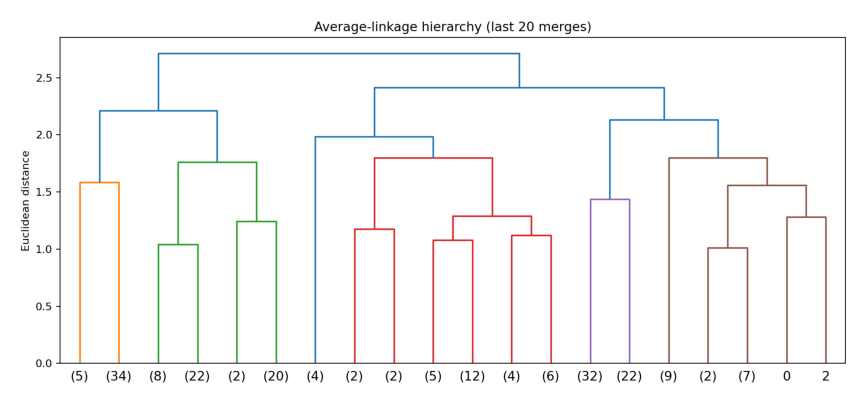

In [8]:
rng=np.random.default_rng(config["kmeans"]["random_state"])
indices=np.arange(len(X))
hierarchy_scores,hierarchy=compare_hierarchical(X[indices],config["kmeans"]["k_values"],model.labels_[indices])
subset_rows=[]
for k in config["kmeans"]["k_values"]:
    candidate=train_model(X[indices],k,config["kmeans"])
    subset_rows.append({"algorithm":"kmeans_full","k":k,"silhouette":float(silhouette_samples(X[indices],candidate.labels_).mean())})
hierarchy_scores=pd.concat([hierarchy_scores,pd.DataFrame(subset_rows)],ignore_index=True)
print(hierarchy_scores.to_string(index=False))
plot_dendrogram(hierarchy,figures / "dendrogram.png")
plt.figure(figsize=(11,5))
plt.imshow(plt.imread(figures / "dendrogram.png"))
plt.axis("off")
plt.show()


## 8. Kết luận

Mall_Customers.csv có 200 khách hợp lệ. K=6 đạt Silhouette 0,4274. Thu nhập theo nghìn USD. Phân cấp so sánh trên cùng 200 khách. Giấy phép Kaggle ghi Other, xem SOURCE.md.

In [9]:
print("Selected K:",model.n_clusters)
print("Best hierarchical K:",int(hierarchy_scores.loc[hierarchy_scores.algorithm=="average_linkage"].sort_values(["silhouette","k"],ascending=[False,True]).iloc[0].k))
print("Outputs:",output)

manifest.update(status="success", selected_k=model.n_clusters,
                silhouette=float(silhouette_samples(X,model.labels_).mean()))
(output / "run.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")


Selected K: 6
Best hierarchical K: 5
Outputs: E:\ML_Nhóm6\Lab03\results\runs\2026-11-18_20-31-41_notebook_273e6c72
